# Logística e SLA

Análise de pedidos com foco em desempenho logístico. São avaliados:

- **Entrega no prazo (OTD):** percentual de pedidos entregues até a data estimada
- **Lead time por fase:** tempo de aprovação, postagem pelo seller e transporte
- **Impacto do atraso na satisfação:** relação entre dias de atraso e nota de avaliação
- **Desempenho por região e rota:** comparação entre UFs de origem (seller) e destino (cliente)



## 1. Importações

#### Instalando as bibliotecas

In [2]:
%pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


#### Importando as bibliotecas

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Carregamento dos dados

#### Carregando os CSVs

In [4]:
PASTA = "../data/"

orders    = pd.read_csv(PASTA + "olist_orders_dataset.csv")
items     = pd.read_csv(PASTA + "olist_order_items_dataset.csv")
reviews   = pd.read_csv(PASTA + "olist_order_reviews_dataset.csv")
customers = pd.read_csv(PASTA + "olist_customers_dataset.csv")
sellers   = pd.read_csv(PASTA + "olist_sellers_dataset.csv")

#### Conferindo o tamanho das tabelas

In [5]:
print("orders:", orders.shape)
print("items:", items.shape)
print("reviews:", reviews.shape)
print("customers:", customers.shape)
print("sellers:", sellers.shape)

orders: (99441, 8)
items: (112650, 7)
reviews: (99224, 7)
customers: (99441, 5)
sellers: (3095, 4)


## 3. Tratamento dos dados

#### Convertendo datas e filtrando entregues

In [6]:
colunas_data = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

for col in colunas_data:
    orders[col] = pd.to_datetime(orders[col])

entregues = orders[orders["order_status"] == "delivered"].copy()

print("Total de pedidos:", len(orders))
print("Entregues:", len(entregues))

Total de pedidos: 99441
Entregues: 96478


#### Padronizando cores 

In [7]:
COR_PRINCIPAL = "#364ef7"
COR_DESTAQUE = "#d23718"
COR_NEUTRA = "#696d8c"

#### Removendo nulos

In [8]:
antes = len(entregues)

entregues = entregues.dropna(subset=[
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
])

print("Removidos por data nula:", antes - len(entregues))
print("Restantes:", len(entregues))

Removidos por data nula: 23
Restantes: 96455


#### Calculando o tempo de cada fase

In [9]:
def dias(fim, inicio):
    return (fim - inicio).dt.total_seconds() / 86400

entregues["dias_aprovacao"]  = dias(entregues["order_approved_at"], entregues["order_purchase_timestamp"])
entregues["dias_postagem"]   = dias(entregues["order_delivered_carrier_date"], entregues["order_approved_at"])
entregues["dias_transporte"] = dias(entregues["order_delivered_customer_date"], entregues["order_delivered_carrier_date"])
entregues["dias_total"]      = dias(entregues["order_delivered_customer_date"], entregues["order_purchase_timestamp"])

#### Removendo negativos

In [10]:
negativos = (
    (entregues["dias_aprovacao"] < 0) |
    (entregues["dias_postagem"] < 0) |
    (entregues["dias_transporte"] < 0)
)

print("Pedidos com tempo negativo:", negativos.sum())

entregues = entregues[~negativos].copy()
print("Restantes:", len(entregues))

Pedidos com tempo negativo: 1373
Restantes: 95082


#### Marcando os outliers com gráfico

99º percentil do prazo total: 46.1 dias
Pedidos acima do 99º percentil: 951
Maior prazo registrado: 209.6 dias


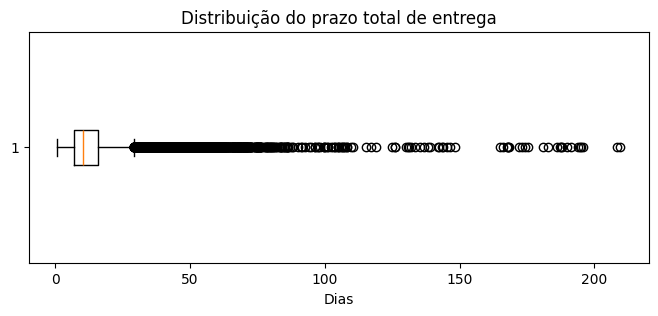

In [11]:
limite = entregues["dias_total"].quantile(0.99)
entregues["outlier"] = entregues["dias_total"] > limite

print(f"99º percentil do prazo total: {limite:.1f} dias")
print("Pedidos acima do 99º percentil:", entregues["outlier"].sum())
print(f"Maior prazo registrado: {entregues['dias_total'].max():.1f} dias")

plt.figure(figsize=(8, 3))
plt.boxplot(entregues["dias_total"], vert=False)
plt.title("Distribuição do prazo total de entrega")
plt.xlabel("Dias")
plt.show()

## 4. Entrega no prazo (OTD)

#### Prazo prometido

In [12]:
entregues["prazo_prometido"] = dias(entregues["order_estimated_delivery_date"], entregues["order_purchase_timestamp"])

#### Atraso

In [13]:
data_real = entregues["order_delivered_customer_date"].dt.normalize()
data_prometida = entregues["order_estimated_delivery_date"].dt.normalize()

entregues["dias_atraso"] = (data_real - data_prometida).dt.days

#### OTD

In [14]:
entregues["no_prazo"] = entregues["dias_atraso"] <= 0

otd = entregues["no_prazo"].mean() * 100

print(f"OTD: {otd:.1f}%")
print(f"Pedidos atrasados: {100 - otd:.1f}%")
print(f"Prazo prometido médio: {entregues['prazo_prometido'].mean():.1f} dias")
print(f"Entrega real média: {entregues['dias_total'].mean():.1f} dias")
print(f"Atraso médio (só dos atrasados): {entregues.loc[~entregues['no_prazo'], 'dias_atraso'].mean():.1f} dias")

OTD: 93.2%
Pedidos atrasados: 6.8%
Prazo prometido médio: 23.7 dias
Entrega real média: 12.6 dias
Atraso médio (só dos atrasados): 10.6 dias


#### Gráfico

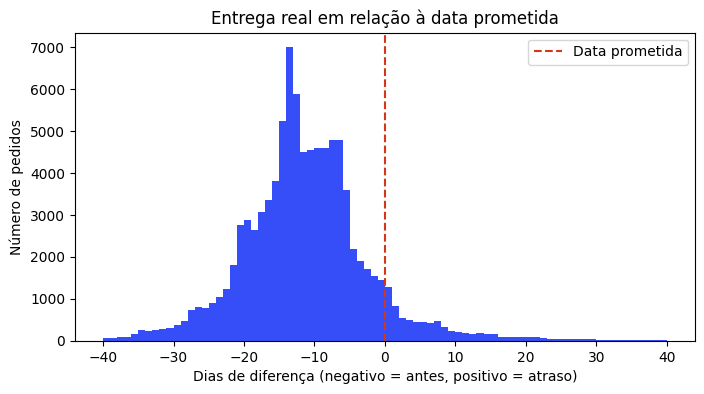

In [15]:
plt.figure(figsize=(8, 4))
plt.hist(entregues["dias_atraso"], bins=range(-40, 41), color=COR_PRINCIPAL)
plt.axvline(0, color=COR_DESTAQUE, linestyle="--", label="Data prometida")
plt.title("Entrega real em relação à data prometida")
plt.xlabel("Dias de diferença (negativo = antes, positivo = atraso)")
plt.ylabel("Número de pedidos")
plt.legend()
plt.show()

## 5. Lead time por fase

#### Tabela com média, mediana e P90

In [16]:
fases = ["dias_aprovacao", "dias_postagem", "dias_transporte", "dias_total"]

resumo = entregues[fases].agg(["mean", "median", lambda x: x.quantile(0.90)]).round(1)
resumo.index = ["Média", "Mediana", "P90"]
resumo

,dias_aprovacao,dias_postagem,dias_transporte,dias_total
Média,0.4,2.9,9.4,12.6
Mediana,0.0,1.8,7.1,10.3
P90,1.4,6.0,18.9,23.2


#### Peso de cada fase no prazo total

In [17]:
medianas = entregues[["dias_aprovacao", "dias_postagem", "dias_transporte"]].median()
percentual = (medianas / medianas.sum() * 100).round(1)

print("Participação de cada fase (pela mediana):")
print(percentual)

Participação de cada fase (pela mediana):
dias_aprovacao      0.2
dias_postagem      20.6
dias_transporte    79.2
dtype: float64


#### Gráfico de mediana e P90 por fase

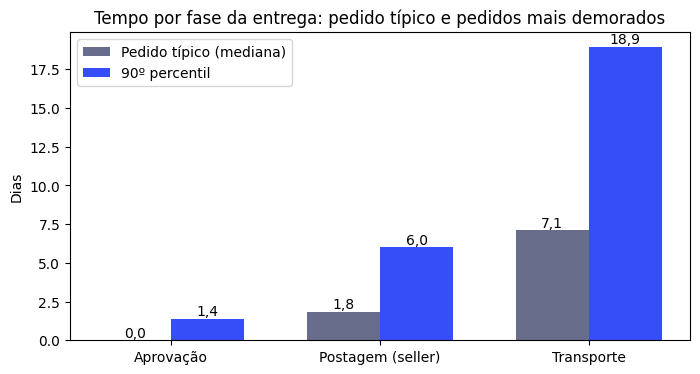

In [18]:
nomes = ["Aprovação", "Postagem (seller)", "Transporte"]
colunas = ["dias_aprovacao", "dias_postagem", "dias_transporte"]

medianas = entregues[colunas].median()
p90 = entregues[colunas].quantile(0.90)

posicao = np.arange(len(nomes))
largura = 0.35

plt.figure(figsize=(8, 4))

plt.bar(
    posicao - largura / 2,
    medianas.values,
    largura,
    label="Pedido típico (mediana)",
    color=COR_NEUTRA
)

plt.bar(
    posicao + largura / 2,
    p90.values,
    largura,
    label="90º percentil",
    color=COR_PRINCIPAL
)

for i in range(len(nomes)):
    plt.text(
        posicao[i] - largura / 2,
        medianas.values[i] + 0.2,
        f"{medianas.values[i]:.1f}".replace(".", ","),
        ha="center"
    )

    plt.text(
        posicao[i] + largura / 2,
        p90.values[i] + 0.2,
        f"{p90.values[i]:.1f}".replace(".", ","),
        ha="center"
    )

plt.xticks(posicao, nomes)
plt.title("Tempo por fase da entrega: pedido típico e pedidos mais demorados")
plt.ylabel("Dias")
plt.legend()
plt.show()

## 6. Desempenho por região e rota

#### Explorando as tabelas e checando os sellers

In [19]:
print("customer_id repetidos em customers:", customers["customer_id"].duplicated().sum())
print("seller_id repetidos em sellers:", sellers["seller_id"].duplicated().sum())
print(customers[["customer_id", "customer_state"]].isna().sum())
print(sellers[["seller_id", "seller_state"]].isna().sum())

sellers_por_pedido = items.groupby("order_id")["seller_id"].nunique()
print("Pedidos com mais de um seller:", (sellers_por_pedido > 1).sum())
print(f"% dos pedidos: {(sellers_por_pedido > 1).mean() * 100:.1f}%")

customer_id repetidos em customers: 0
seller_id repetidos em sellers: 0
customer_id       0
customer_state    0
dtype: int64
seller_id       0
seller_state    0
dtype: int64
Pedidos com mais de um seller: 1278
% dos pedidos: 1.3%


#### Montando a base de rotas

In [20]:
por_pedido = items.groupby("order_id").agg(
    seller_id=("seller_id", "first"),
    n_sellers=("seller_id", "nunique"),
    frete=("freight_value", "sum"),
    valor_produtos=("price", "sum"),
).reset_index()

por_pedido = por_pedido[por_pedido["n_sellers"] == 1]

logistica = (
    entregues
    .merge(por_pedido, on="order_id", how="inner")
    .merge(customers[["customer_id", "customer_state"]], on="customer_id", how="left")
    .merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left")
)

logistica["rota"] = logistica["seller_state"] + " → " + logistica["customer_state"]
logistica["tipo_rota"] = np.where(logistica["seller_state"] == logistica["customer_state"], "Mesma UF", "Entre UFs")
logistica["frete_pct"] = logistica["frete"] / logistica["valor_produtos"] * 100

grupos = {
    "Norte": ["AC", "AP", "AM", "PA", "RO", "RR", "TO"],
    "Nordeste": ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"],
    "Centro-Oeste": ["DF", "GO", "MT", "MS"],
    "Sudeste": ["ES", "MG", "RJ", "SP"],
    "Sul": ["PR", "RS", "SC"],
}
regioes = {uf: regiao for regiao, ufs in grupos.items() for uf in ufs}
logistica["regiao"] = logistica["customer_state"].map(regioes)

print("Pedidos entregues:", len(entregues))
print("Pedidos na base de rotas:", len(logistica))
print("Pedidos sem UF ou região:", logistica[["customer_state", "seller_state", "regiao"]].isna().sum().sum())
print("order_id repetidos:", logistica["order_id"].duplicated().sum())

Pedidos entregues: 95082
Pedidos na base de rotas: 93859
Pedidos sem UF ou região: 0
order_id repetidos: 0


#### Desempenho por região do país

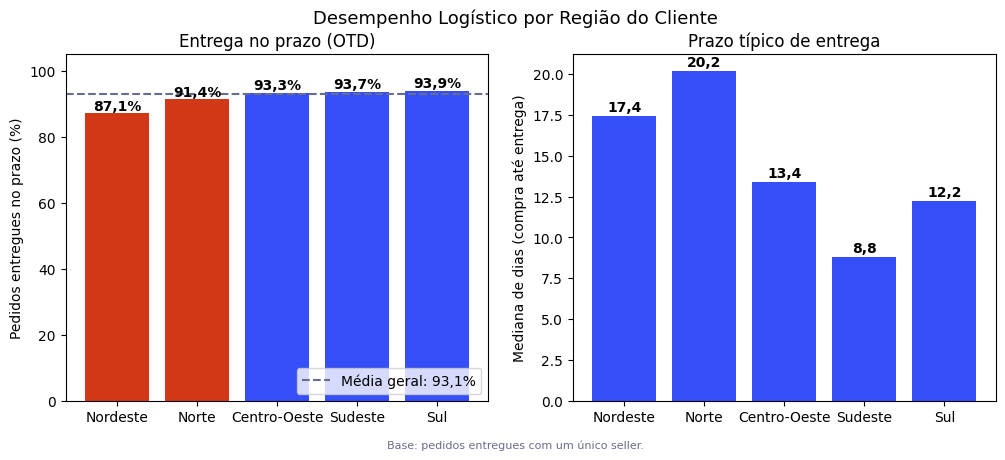

In [21]:
def resumo(df, coluna):
    return df.groupby(coluna).agg(
        pedidos=("order_id", "count"),
        atrasados=("no_prazo", lambda s: (~s).sum()),
        otd=("no_prazo", lambda s: s.mean() * 100),
        mediana_dias=("dias_total", "median"),
        mediana_transporte=("dias_transporte", "median"),
        frete_pct=("frete_pct", "median"),
    ).round(1)


otd_geral = logistica["no_prazo"].mean() * 100

por_regiao = resumo(logistica, "regiao").sort_values("otd")

cores = [
    COR_DESTAQUE if v < otd_geral else COR_PRINCIPAL
    for v in por_regiao["otd"]
]

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))

barras = eixos[0].bar(
    por_regiao.index, por_regiao["otd"], color=cores
)

eixos[0].axhline(
    otd_geral,
    color=COR_NEUTRA,
    linestyle="--",
    label=f"Média geral: {otd_geral:.1f}%".replace(".", ",")
)

for barra, v in zip(barras, por_regiao["otd"]):
    eixos[0].text(
        barra.get_x() + barra.get_width() / 2,
        v + 1,
        f"{v:.1f}%".replace(".", ","),
        ha="center",
        fontweight="bold"
    )

eixos[0].set_ylim(0, 105)
eixos[0].set_ylabel("Pedidos entregues no prazo (%)")
eixos[0].set_title("Entrega no prazo (OTD)")
eixos[0].legend(loc="lower right")

barras = eixos[1].bar(
    por_regiao.index,
    por_regiao["mediana_dias"],
    color=COR_PRINCIPAL
)

for barra, v in zip(barras, por_regiao["mediana_dias"]):
    eixos[1].text(
        barra.get_x() + barra.get_width() / 2,
        v + 0.3,
        f"{v:.1f}".replace(".", ","),
        ha="center",
        fontweight="bold"
    )

eixos[1].set_ylabel("Mediana de dias (compra até entrega)")
eixos[1].set_title("Prazo típico de entrega")

plt.suptitle(
    "Desempenho Logístico por Região do Cliente",
    fontsize=13
)

fig.text(
    0.5, 0.005,
    "Base: pedidos entregues com um único seller.",
    ha="center",
    fontsize=8,
    color=COR_NEUTRA
)

plt.show()

#### Desempenho por estado de destino

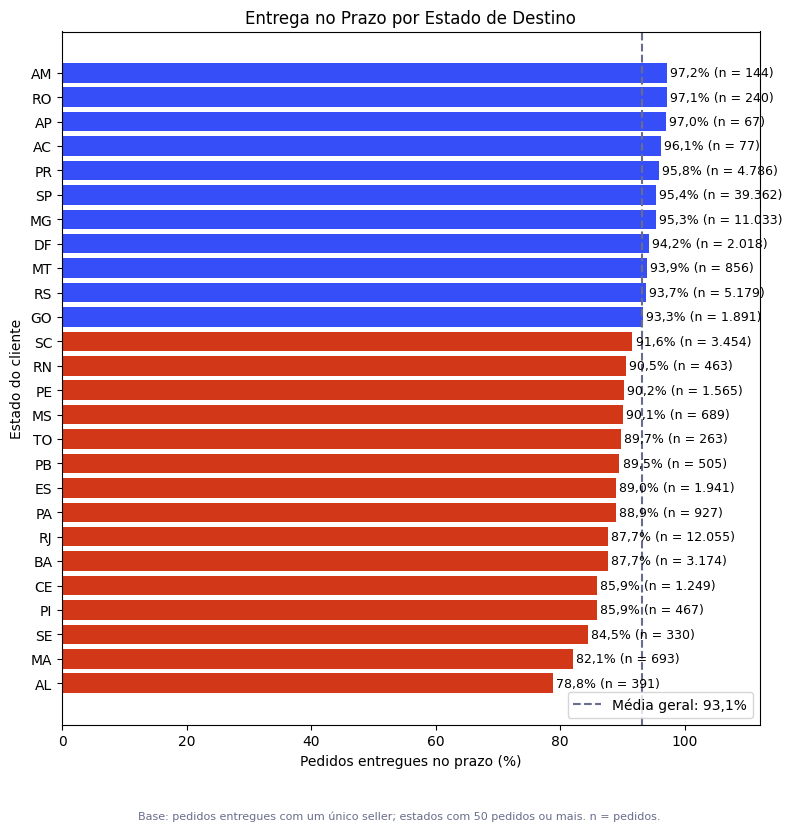

In [22]:
por_uf = resumo(logistica, "customer_state")
por_uf = por_uf[por_uf["pedidos"] >= 50].sort_values("otd")

cores = [
    COR_DESTAQUE if v < otd_geral else COR_PRINCIPAL
    for v in por_uf["otd"]
]

fig, ax = plt.subplots(figsize=(9, 9))

barras = ax.barh(por_uf.index, por_uf["otd"], color=cores)

ax.axvline(
    otd_geral,
    color=COR_NEUTRA,
    linestyle="--",
    label=f"Média geral: {otd_geral:.1f}%".replace(".", ",")
)

for barra, v, n in zip(barras, por_uf["otd"], por_uf["pedidos"]):
    ax.text(
        v + 0.5,
        barra.get_y() + barra.get_height() / 2,
        f"{v:.1f}% (n = {int(n):,})".replace(",", ".").replace(".", ",", 1),
        va="center",
        fontsize=9
    )

ax.set_xlim(0, 112)
ax.set_xlabel("Pedidos entregues no prazo (%)")
ax.set_ylabel("Estado do cliente")
ax.legend(loc="lower right")

plt.title("Entrega no Prazo por Estado de Destino")

fig.text(
    0.5, 0.005,
    "Base: pedidos entregues com um único seller; estados com 50 pedidos ou mais. n = pedidos.",
    ha="center",
    fontsize=8,
    color=COR_NEUTRA
)

plt.show()

## 8. Conclusões e recomendações

**Resumo:** a Olist cumpre a data prometida em 93,2% dos pedidos, mas só porque promete quase o dobro do tempo que leva. Os poucos atrasos são longos, derrubam a nota do cliente e se concentram no Nordeste e no Rio de Janeiro.

### Conclusões

**1. A promessa é cumprida, com muita folga.** 93,2% dos pedidos chegam até a data prometida, e 6,8% atrasam. A Olist promete em média 23,7 dias e entrega em 12,6, ou seja, 11 dias antes.

**2. Os atrasos são poucos, mas longos.** Quando o pedido atrasa, atrasa em média 10,6 dias.

**3. O transporte é o gargalo.** O pedido típico leva 10,3 dias, e o transporte responde por cerca de 79% desse tempo (7,1 dias). A postagem pelo seller pesa cerca de 21% (1,8 dia), e a aprovação é praticamente imediata. Nove em cada dez pedidos chegam em até 23,2 dias, e os 10% mais lentos levam mais que isso. Transporte (18,9 dias) e postagem (6,0 dias, mais de 3 vezes o tempo típico) são as fases em que os pedidos mais demorados se afastam do normal.

**4. O atraso custa satisfação.** Segundo a análise de Satisfação do Cliente, pedidos entregues no prazo têm nota média de 4,29, e os atrasados, 2,57: 1,72 ponto a menos (cerca de 40%). Os atrasados são minoria (cerca de 8% das avaliações), mas pesam muito na percepção do cliente. Essa é uma associação observada nos dados, e não prova que o atraso seja a única causa.

**5. O Nordeste e o Rio de Janeiro concentram o problema.**
- **Nordeste:** menor taxa de entrega no prazo entre as regiões (87,1%) e prazo típico de 17,4 dias. Os nove estados da região ficam abaixo da média nacional, e os piores são Alagoas (78,8%), Maranhão (82,1%) e Sergipe (84,5%).
- **Rio de Janeiro:** 87,7% no prazo, com cerca de 12 mil pedidos, o segundo maior volume do país, atrás só de São Paulo (95,4%). Puxa para baixo o resultado do Sudeste.
- **Sudeste, Sul e Centro-Oeste:** entre 93,3% e 93,9% no prazo. O Sudeste tem o prazo típico mais curto (8,8 dias).

**6. A promessa não acompanha a realidade em todas as regiões.** O Norte tem o prazo típico mais longo (20,2 dias), mas 91,4% no prazo, o que indica que o prazo prometido para a região já é longo. O Nordeste demora menos (17,4 dias) e, mesmo assim, atrasa mais, o que indica que a promessa ali é apertada para o que a logística entrega.

### Recomendações

**1. Calibrar a promessa de prazo, região por região.**
- *Evidência:* promete-se 23,7 dias e entrega-se em 12,6.
- *Ação:* revisar a estimativa por região, começando pelas de entrega mais rápida, e ampliar o prazo apenas no Nordeste, onde a promessa está apertada. Prazos mais curtos podem tornar a oferta mais atraente, mas os dados não medem efeito nas vendas, então vale testar em escala pequena antes de aplicar a toda a base.
- *Indicador:* prazo prometido médio vs. entrega real, por região.

**2. Priorizar o Nordeste e o Rio de Janeiro.**
- *Evidência:* Nordeste com 87,1% no prazo e todos os estados abaixo da média, e Rio de Janeiro com 87,7% em 12 mil pedidos.
- *Ação:* renegociar prazos e metas de entrega com as transportadoras dessas regiões, avaliar um ponto de distribuição no Nordeste e investigar por que o Rio de Janeiro destoa do resto do Sudeste.
- *Indicador:* entrega no prazo por estado.

**3. Evitar os atrasos longos.**
- *Evidência:* atraso médio de 10,6 dias nos pedidos atrasados, e nota média de 2,57 contra 4,29 dos entregues no prazo.
- *Ação:* identificar cedo os pedidos em risco (por exemplo, postagem lenta) e avisar o cliente antes que a data prometida passe.
- *Indicador:* percentual de pedidos com mais de 7 dias de atraso e nota média dos atrasados.

**4. Acompanhar o tempo de postagem dos sellers.**
- *Evidência:* o seller despacha em 1,8 dia no pedido típico, mas 10% levam mais de 6 dias.
- *Ação:* definir um prazo máximo de despacho e acompanhar os sellers que passam dele.
- *Indicador:* tempo de postagem por seller.

### Limitações

- Atraso e nota baixa andam juntos, mas isso não prova causa: produto com defeito, por exemplo, também gera nota baixa.
- Os dados cobrem 2016 a 2018, e a logística brasileira mudou desde então.
- **Qualidade dos dados:** foram removidos 23 pedidos sem data e 1.373 (1,4%) com datas inconsistentes. Os 951 pedidos acima de 46,1 dias (99º percentil, máximo de 209,6 dias) foram mantidos, por serem atrasos reais.
- **Análise por região:** exclui 1.223 pedidos com mais de um vendedor, e mostra só estados com 50 pedidos ou mais. Estados pequenos, como Amazonas, Rondônia, Amapá e Acre (entre 67 e 240 pedidos), têm resultados menos estáveis.
- **Definição de atraso:** nesta análise, compara-se só a data (a hora é ignorada), o que dá 6,8% de atrasados. A análise de Satisfação do Cliente compara data e hora, e por isso o percentual de atrasados é um pouco maior (cerca de 8%).
- **Ainda não medido:** quanto do atraso vem do seller e quanto vem da transportadora, e o desempenho por rota (estado de origem → destino).